In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from lightning.pytorch.utilities.types import OptimizerLRScheduler
from torch.optim import SGD

import lightning as L
from lightning.pytorch.tuner import Tuner
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
class BasicLightning(L.LightningModule):
    def __init__(self):
        super().__init__()

        self.w00 = nn.Parameter(torch.tensor(1.7), requires_grad=False)
        self.b00 = nn.Parameter(torch.tensor(-0.85), requires_grad=False)
        self.w01 = nn.Parameter(torch.tensor(-40.8), requires_grad=False)

        self.w10 = nn.Parameter(torch.tensor(12.6), requires_grad=False)
        self.b10 = nn.Parameter(torch.tensor(0.0), requires_grad=False)
        self.w11 = nn.Parameter(torch.tensor(2.7), requires_grad=False)

        self.final_bias = nn.Parameter(torch.tensor(-16.), requires_grad=False)

    def forward(self, input):
        input_to_top_relu = input * self.w00 + self.b00
        tob_relu_output = F.relu(input_to_top_relu)
        scaled_top_relu_output = tob_relu_output * self.w01

        input_to_bottom_relu = input * self.w10 + self.b10
        bottom_relu_output = F.relu(input_to_bottom_relu)
        scaled_bottom_relu_output = bottom_relu_output * self.w11

        input_to_final_relu = scaled_top_relu_output + scaled_bottom_relu_output + self.final_bias

        output = F.relu(input_to_final_relu)
        return output

Text(0.5, 0, 'Dose')

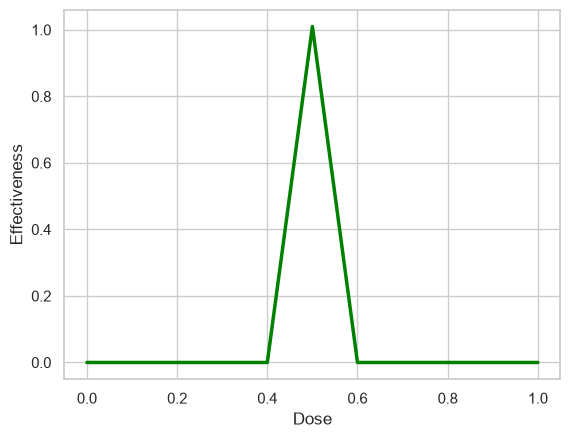

In [4]:
input_doses = torch.linspace(start=0, end=1, steps=11)

model = BasicLightning()

output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values,
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")

In [20]:
class BasicLightningTrain(L.LightningModule):
    def __init__(self):
        super().__init__()

        self.w00 = nn.Parameter(torch.tensor(1.7), requires_grad=False)
        self.b00 = nn.Parameter(torch.tensor(-0.85), requires_grad=False)
        self.w01 = nn.Parameter(torch.tensor(-40.8), requires_grad=False)

        self.w10 = nn.Parameter(torch.tensor(12.6), requires_grad=False)
        self.b10 = nn.Parameter(torch.tensor(0.0), requires_grad=False)
        self.w11 = nn.Parameter(torch.tensor(2.7), requires_grad=False)

        self.final_bias = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        self.learning_rate = 0.01

    def forward(self, input):
        input_to_top_relu = input * self.w00 + self.b00
        tob_relu_output = F.relu(input_to_top_relu)
        scaled_top_relu_output = tob_relu_output * self.w01

        input_to_bottom_relu = input * self.w10 + self.b10
        bottom_relu_output = F.relu(input_to_bottom_relu)
        scaled_bottom_relu_output = bottom_relu_output * self.w11

        input_to_final_relu = scaled_top_relu_output + scaled_bottom_relu_output + self.final_bias

        output = F.relu(input_to_final_relu)
        return output

    def configure_optimizers(self):
        return SGD(self.parameters(), lr=self.learning_rate)

    def training_step(self, batch, batch_idx):
        input_i, label_i = batch
        output_i = self.forward(input_i)
        loss = (output_i - label_i)**2

        return loss

Text(0.5, 0, 'Dose')

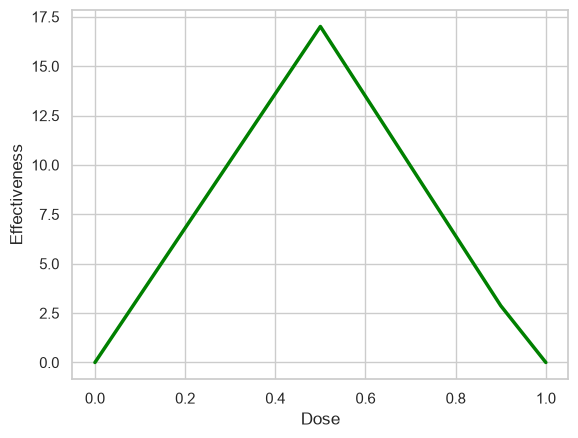

In [21]:
input_doses = torch.linspace(start=0, end=1, steps=11)

model = BasicLightningTrain()

output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values.detach(),
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")

In [30]:
inputs = torch.tensor([0., 0.5, 1.])
labels = torch.tensor([0., 1., 0.])

dataset = TensorDataset(inputs, labels)
dataloader = DataLoader(dataset)

optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

model = BasicLightningTrain()
trainer = L.Trainer(max_epochs=1000, accelerator="auto", devices="auto")
tuner = Tuner(trainer)
lr_find_results = tuner.lr_find(model,
                                        train_dataloaders=dataloader,
                                        min_lr=0.001,
                                        max_lr=1.0,
                                        early_stop_threshold=None)

new_lr = lr_find_results.suggestion()
print(f"lr_find() suggests {new_lr:.5f} for the learning rate")

model.learning_rate = new_lr


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
`weights_only` was not set, defaulting to `False`.
Finding best initial lr: 100%|██████████| 100/100 [00:00<00:00, 660.39it/s]
Restoring states from the checkpoint path at C:\Users\God -01.11\Desktop\AI Course\7-Neural Networks\NeuralNetworkFromSkratch\.lr_find_4258fa34-8c96-4eb8-ba08-205532c88ce2.ckpt
Restored all states from the checkpoint at C:\Users\God -01.11\Desktop\AI Course\7-Neural Networks\NeuralNetworkFromSkratch\.lr_find_4258fa34-8c96-4eb8-ba08-205532c88ce2.ckpt
Learning ra

lr_find() suggests 0.00214 for the learning rate


In [31]:
trainer.fit(model, train_dataloaders=dataloader)

print(model.final_bias.data)


  | Name         | Type | Params | Mode | FLOPs
-----------------------------------------------------
  | other params | n/a  | 7      | n/a  | n/a  
-----------------------------------------------------
1         Trainable params
6         Non-trainable params
7         Total params
0.000     Total estimated model params size (MB)
0         Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 999: 100%|██████████| 3/3 [00:00<00:00, 251.95it/s, v_num=5]

`Trainer.fit` stopped: `max_epochs=1000` reached.


Epoch 999: 100%|██████████| 3/3 [00:00<00:00, 160.86it/s, v_num=5]
tensor(-15.7895)


Text(0.5, 0, 'Dose')

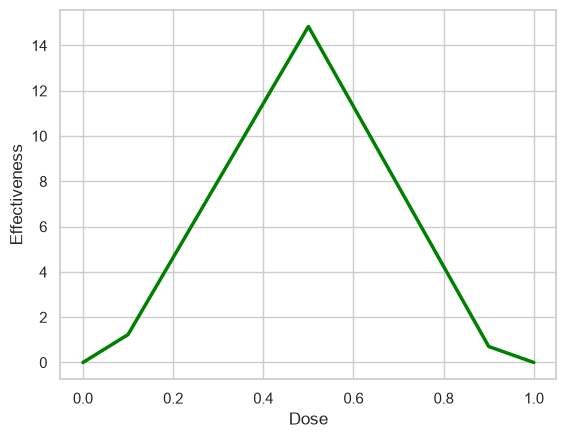

In [27]:
output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values.detach(),
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")